# Low-resolution double-basin PG prototype

This production-oriented notebook solves an idealized version of the attached two-basin sketch. Two deep bowls are separated by a shallow central ridge that extends westward from the eastern shelf, leaving a deeper western gateway analogous to Fram Strait. The outer shallow region represents a continental shelf.

The calculation uses a constant Coriolis parameter (an $f$ plane) and cyclonic wind-stress cells over both basins. Expensive adjoint, perturbation, and external-theory checks from `PG_API_Example.ipynb` are omitted. The depth-integrated momentum and three equivalent vorticity-budget closure diagnostics are retained.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy
using Plots
using Statistics
import Contour
using Test

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


## Fast prototype controls

Increase `mesh_resolution`, `horizontal_points`, `vertical_points`, and `diagnostic_points` only after the geometry and forcing have been finalized. Disk output is disabled by default.

In [15]:
# Low resolution testing:
# mesh_resolution = 0.16
# horizontal_points = 33
# vertical_points = 25
# diagnostic_points = 17
# SAVE_OUTPUT = false

# Medium resolution testing:
# mesh_resolution = 0.08
# horizontal_points = 65
# vertical_points = 49
# diagnostic_points = 33
# SAVE_OUTPUT = false

# High resolution testing:
mesh_resolution = 0.02
horizontal_points = 128
vertical_points = 97
diagnostic_points = 65
SAVE_OUTPUT = false

output_path(name) = SAVE_OUTPUT ? joinpath(@__DIR__, name) : nothing

output_path (generic function with 1 method)

## Idealized double-basin geometry and forcing

The bathymetry is a shallow perimeter shelf plus northern and southern Gaussian deep basins. An elongated shallow Barents shelf projects westward across the central/eastern basin, leaving a narrow, basin-depth Fram Strait channel in the western third. A smooth elliptical taper forces every deep feature to vanish at the outer boundary. All depth derivatives are supplied analytically. The two compact wind-stress cells have positive (cyclonic) curl near their basin centers.

In [3]:
Lx, Ly = 2.0, 2.8
ax, ay = Lx / 2, Ly / 2
Ek = 0.02
Γ = 0.20
boundary = ellipse_boundary(ax, ay; points=64)
parameters = PGParameters(Ek, Γ; viscosity=1.0, diffusivity=1.0)

gaussian(x, y, cx, cy, sx, sy) = exp(-((x - cx) / sx)^2 - ((y - cy) / sy)^2)
gaussian_x(x, y, cx, cy, sx, sy) =
    -2(x - cx) / sx^2 * gaussian(x, y, cx, cy, sx, sy)
gaussian_y(x, y, cx, cy, sx, sy) =
    -2(y - cy) / sy^2 * gaussian(x, y, cx, cy, sx, sy)

shelf_depth = 0.26
shelf_width = 0.18
western_shelf_extra_width = 0.50
western_shelf_transition = -0.45
western_shelf_transition_width = 0.15
north_basin = (amplitude=0.96, cx=0.01, cy=0.69, sx=0.62, sy=0.455)
south_basin = (amplitude=0.96, cx=0.01, cy=-0.69, sx=0.62, sy=0.455)
deep_basins = (north_basin, south_basin)

# This westward-deepening sigmoid is nearly flat over the Barents shelf.
# The outer taper closes it against the western shelf, making Fram Strait
# a saddle rather than a locally deepest hole.
fram_amplitude = 1.30
fram_transition = -0.54
fram_width = 0.10
fram_deepening(x) = fram_amplitude / (1 + exp((x - fram_transition) / fram_width))
fram_deepening_x(x) = -(fram_amplitude / fram_width) *
    exp((x - fram_transition) / fram_width) /
    (1 + exp((x - fram_transition) / fram_width))^2

local_shelf_width(x) = shelf_width + western_shelf_extra_width /
    (1 + exp((x - western_shelf_transition) / western_shelf_transition_width))
local_shelf_width_x(x) = -(western_shelf_extra_width / western_shelf_transition_width) *
    exp((x - western_shelf_transition) / western_shelf_transition_width) /
    (1 + exp((x - western_shelf_transition) / western_shelf_transition_width))^2
elliptical_radius_squared(x, y) = (x / ax)^2 + (y / ay)^2
interior_taper(x, y) = begin
    radius = 1 - elliptical_radius_squared(x, y)
    width = local_shelf_width(x)
    1 - exp(-(radius / width)^2)
end
interior_taper_x(x, y) = begin
    radius = 1 - elliptical_radius_squared(x, y)
    width = local_shelf_width(x)
    width_x = local_shelf_width_x(x)
    exp(-(radius / width)^2) * (
        -4x * radius / (ax^2 * width^2) -
        2radius^2 * width_x / width^3
    )
end
interior_taper_y(x, y) = begin
    radius = 1 - elliptical_radius_squared(x, y)
    width = local_shelf_width(x)
    -4y * radius / (ay^2 * width^2) * exp(-(radius / width)^2)
end

deepening(x, y) = sum(
    feature.amplitude * gaussian(x, y, feature.cx, feature.cy, feature.sx, feature.sy)
    for feature in deep_basins
) + fram_deepening(x)
deepening_x(x, y) = sum(
    feature.amplitude * gaussian_x(x, y, feature.cx, feature.cy, feature.sx, feature.sy)
    for feature in deep_basins
) + fram_deepening_x(x)
deepening_y(x, y) = sum(
    feature.amplitude * gaussian_y(x, y, feature.cx, feature.cy, feature.sx, feature.sy)
    for feature in deep_basins
)

depth(x, y) = shelf_depth + interior_taper(x, y) * deepening(x, y)
depth_x(x, y) =
    interior_taper_x(x, y) * deepening(x, y) + interior_taper(x, y) * deepening_x(x, y)
depth_y(x, y) =
    interior_taper_y(x, y) * deepening(x, y) + interior_taper(x, y) * deepening_y(x, y)

f0 = 1.0
stress_amplitude = 1e-3
wind_cells = (
    (cx=north_basin.cx, cy=north_basin.cy, sx=0.55, sy=0.52),
    (cx=south_basin.cx, cy=south_basin.cy, sx=0.57, sy=0.50),
)
stress_envelope(x, y, cell) = gaussian(x, y, cell.cx, cell.cy, cell.sx, cell.sy)
wind_stress(x, y) = sum(
    stress_amplitude * stress_envelope(x, y, cell) *
    (-(y - cell.cy) / cell.sy + im * (x - cell.cx) / cell.sx)
    for cell in wind_cells
)
wind_stress_curl(x, y) = sum(
    stress_amplitude * stress_envelope(x, y, cell) * (
        (1 - 2((x - cell.cx) / cell.sx)^2) / cell.sx +
        (1 - 2((y - cell.cy) / cell.sy)^2) / cell.sy
    ) for cell in wind_cells
)

problem = PGProblem(
    parameters=parameters,
    depth=depth,
    depth_x=depth_x,
    depth_y=depth_y,
    coriolis=(x, y) -> f0,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> 0.0,
    wind_stress=wind_stress,
    wind_stress_curl=wind_stress_curl,
    restoring_buoyancy=(x, y, z) -> 1e-2z,
    surface_buoyancy=(x, y) -> 2e-3 * y / Ly,
    boundary=boundary,
)

PGProblem{PGParameters{Float64}, typeof(depth), var"#32#33", var"#34#35", var"#36#37", typeof(wind_stress), typeof(wind_stress_curl), var"#38#39", var"#40#41", typeof(depth_x), typeof(depth_y), Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#124#125"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.02, 0.2, 1.0, 1.0), Main.depth, var"#32#33"(), var"#34#35"(), var"#36#37"(), Main.wind_stress, Main.wind_stress_curl, var"#38#39"(), var"#40#41"(), Main.depth_x, Main.depth_y, [(1.0, 0.0), (0.9951847266721969, 0.13722399646138483), (0.9807852804032304, 0.2731264508225795), (0.9569403357322088, 0.40639854815624726), (0.9238795325112867, 0.5357568053111257), (0.881921264348355, 0.6599554315563967), (0.8314696123025452, 0.777798326227443), (0.773010453362737, 0.8881505978291037), (0.7071067811865476, 0.9899494936611664), (0.6343932841636455, 1.0822146347078316)  …  (0.5555702330196018, -1.1640574572235636), (0.6343932841636456, -1.0822146347078316), (0.7071067811865474, -0.98

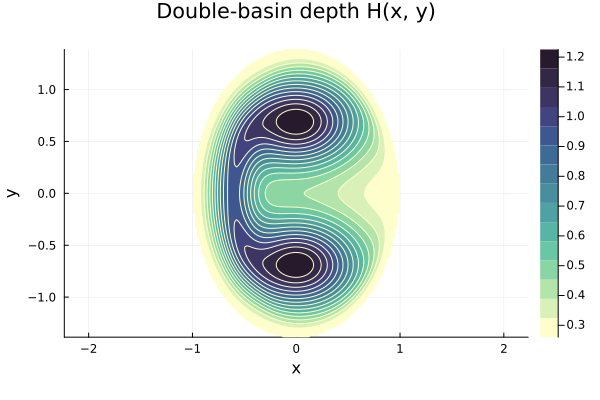

In [4]:
geometry_x = range(-0.99ax, 0.99ax; length=101)
geometry_y = range(-0.99ay, 0.99ay; length=141)
geometry_depth = [
    problem.inside(xx, yy) ? depth(xx, yy) : NaN
    for yy in geometry_y, xx in geometry_x
]
geometry_figure = contourf(
    geometry_x, geometry_y, geometry_depth;
    levels=14, color=:deep, aspect_ratio=:equal,
    xlabel="x", ylabel="y", title="Double-basin depth H(x, y)",
)
display(geometry_figure)

## Ekman-layer depth

For this nondimensional model, $\alpha=\sqrt{|f|/(2\nu\,\mathrm{Ek})}$ and the Ekman-layer depth is $\delta_E=1/\alpha$.

In [5]:
ekman_layer_depth(x, y) = sqrt(
    2parameters.viscosity * parameters.Ek / abs(problem.coriolis(x, y)),
)
wet_geometry_depth = filter(isfinite, vec(geometry_depth))
ekman_depth = ekman_layer_depth(0.0, 0.0)
ekman_layer_report = (
    Ek=parameters.Ek,
    viscosity=parameters.viscosity,
    coriolis=f0,
    nondimensional_ekman_layer_depth=ekman_depth,
    minimum_water_depth=minimum(wet_geometry_depth),
    maximum_water_depth=maximum(wet_geometry_depth),
    minimum_depth_in_ekman_layers=minimum(wet_geometry_depth) / ekman_depth,
    maximum_depth_in_ekman_layers=maximum(wet_geometry_depth) / ekman_depth,
)
display(ekman_layer_report)

(Ek = 0.02, viscosity = 1.0, coriolis = 1.0, nondimensional_ekman_layer_depth = 0.2, minimum_water_depth = 0.26001026928280563, maximum_water_depth = 1.2256459489860272, minimum_depth_in_ekman_layers = 1.300051346414028, maximum_depth_in_ekman_layers = 6.1282297449301355)

## Solve and sample

The pressure mesh and three-dimensional sampling grids are deliberately coarse for rapid iteration.

┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.02
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/double_basin_prototype_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:237
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 10%] Meshing curve 3 (Line)
Info    : [ 10%] Meshing curve 4 (Line)
Info    : [ 10%] Meshing curve 5 (Line)
Info    : [ 10%] Meshing curve 6 (Line)
Info    : [ 10%] Meshing curve 7 (Line)
Info    : [ 20%] Meshing curve 8 (Line)
Info    : [ 20%] Meshing curve 9 (Line)
Info    : [ 20%] Meshing curve 10 (Line)
Info    : [ 20%] Meshing curve 11 (Line)
Info    : [ 20%] Meshing curve 12 (Line)
Info    : [ 20%] Meshing curve 13 (Line)
Info    : [ 30%] Meshing curve 14 (Line)
Info    : [ 30%] Meshing curve 15 (Line)
Info    : [ 30%] Meshing curve 16 (Line)
Info    : [ 30%] Meshing curve 17 (Line)
Info    : [ 30%] Meshing curve 18 (Line)
Info    : [ 30%] Meshing curve 19 (Line)
Info    : [ 30%] Meshing curve 20 (Line)
Info    : [ 40%] Meshing curve 21 (Line)
Info    : [ 40%] Meshing curve 22 (Line)
Info    : [ 40%] Meshing curve 23 (Line)
Info    : [ 40%] Meshing curve 24 (Line)
I

┌ Info: Completed generating surface mesh
│   seconds = 0.247
│   allocated_mib = 3.54
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16


Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/double_basin_prototype_pressure.msh'...
Info    : 129 entities
Info    : 15144 nodes
Info    : 30286 elements
Info    : Done reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/double_basin_prototype_pressure.msh'


┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Surface-pressure solve started
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/double_basin_prototype_pressure.msh
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:163
┌ Info: Starting loading Gridap surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documen

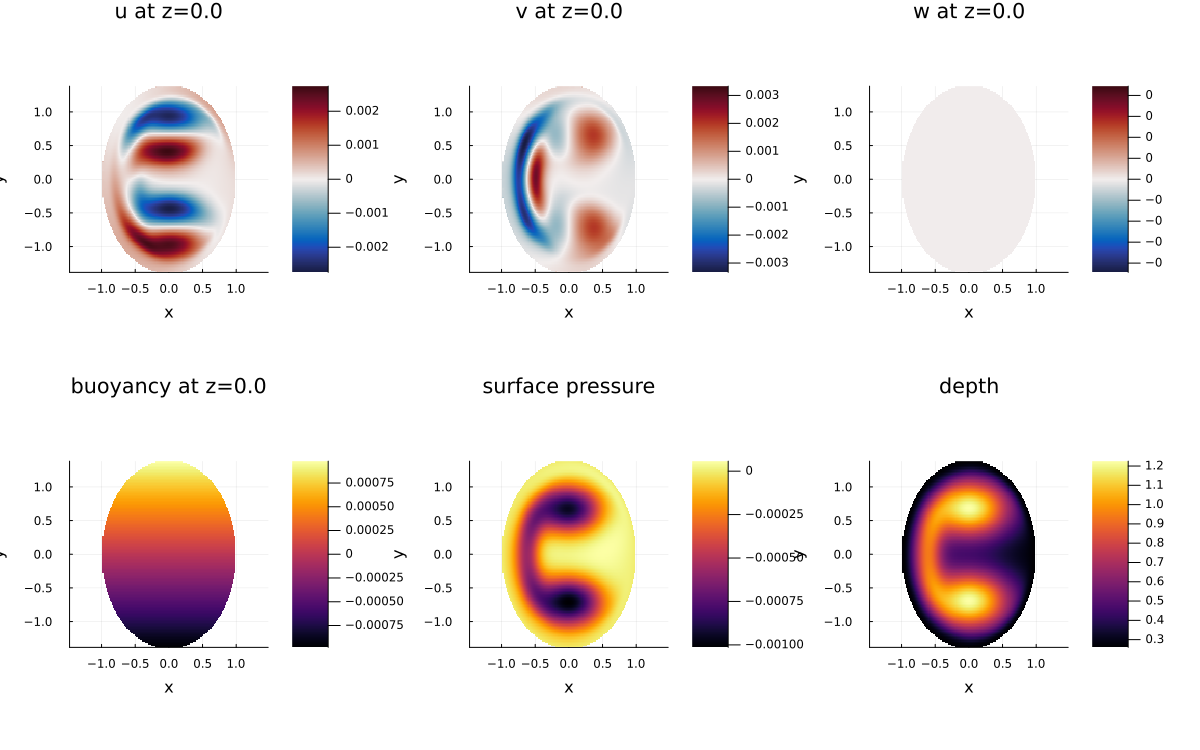

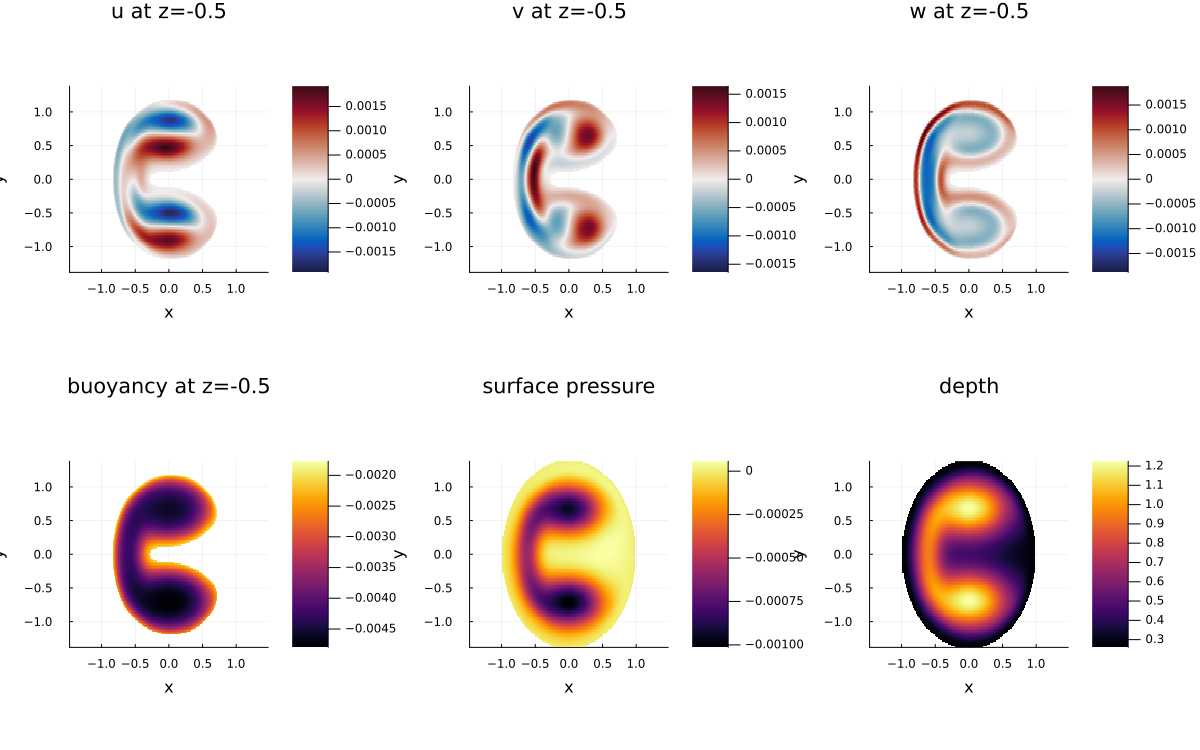

In [6]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "double_basin_prototype_pressure.msh"),
    mesh_resolution=mesh_resolution,
    overwrite_mesh=true,
)

x = range(-0.98ax, 0.98ax; length=horizontal_points)
y = range(-0.98ay, 0.98ay; length=horizontal_points)
maximum_depth = maximum(depth(xx, yy) for yy in y, xx in x if problem.inside(xx, yy))
middepth_z = -0.5
z = sort!(unique!(vcat(
    collect(range(-maximum_depth, 0.0; length=vertical_points)),
    middepth_z,
)))
fields = sample_solution(solution, x, y, z)

surface_figure = plot_solution(
    fields;
    output=output_path("double_basin_surface_fields.png"),
)
middepth_figure = plot_solution(
    fields;
    z_index=findfirst(==(middepth_z), fields.z),
    output=output_path("double_basin_middepth_fields.png"),
)
display(surface_figure)
display(middepth_figure)

if SAVE_OUTPUT
    display(write_solution(fields, joinpath(@__DIR__, "double_basin")))
end

## Forcing fields

Plot the two wind-stress components, wind-stress curl, stress magnitude, prescribed surface buoyancy, and interior restoring buoyancy at the fixed level $z=-0.5$.

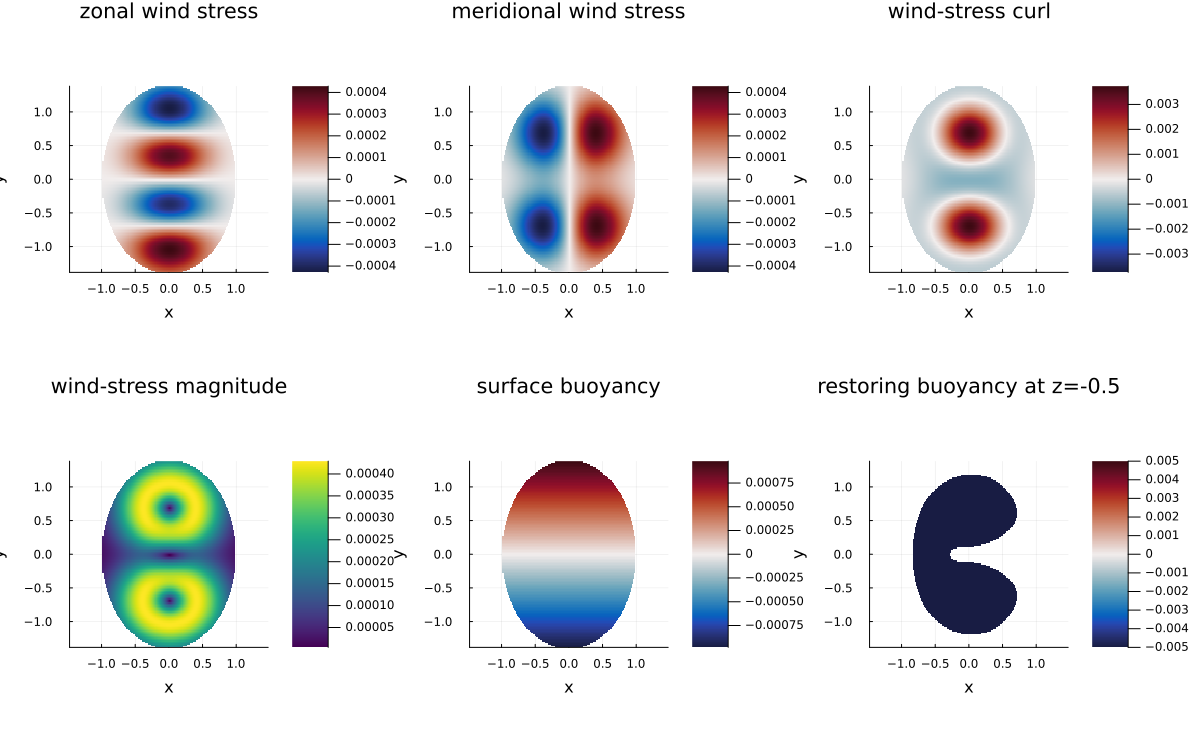

In [7]:
forcing_wet = [problem.inside(xx, yy) for xx in x, yy in y]
forcing_field(fn) = [forcing_wet[i, j] ? fn(x[i], y[j]) : NaN for i in eachindex(x), j in eachindex(y)]
τx = forcing_field((xx, yy) -> real(wind_stress(xx, yy)))
τy = forcing_field((xx, yy) -> imag(wind_stress(xx, yy)))
τcurl = forcing_field(wind_stress_curl)
τmagnitude = hypot.(τx, τy)
surface_buoyancy_forcing = forcing_field(problem.surface_buoyancy)
middepth_restoring = [
    forcing_wet[i, j] && depth(x[i], y[j]) >= -middepth_z ?
        problem.restoring_buoyancy(x[i], y[j], middepth_z) : NaN
    for i in eachindex(x), j in eachindex(y)
]

function forcing_map(values, title; signed=false)
    finite = filter(isfinite, vec(values))
    options = signed ? (
        color=:balance,
        clims=(-maximum(abs, finite), maximum(abs, finite)),
    ) : (color=:viridis,)
    return heatmap(
        x, y, values'; xlabel="x", ylabel="y", title=title,
        aspect_ratio=:equal, options...,
    )
end

forcing_figure = plot(
    forcing_map(τx, "zonal wind stress"; signed=true),
    forcing_map(τy, "meridional wind stress"; signed=true),
    forcing_map(τcurl, "wind-stress curl"; signed=true),
    forcing_map(τmagnitude, "wind-stress magnitude"),
    forcing_map(surface_buoyancy_forcing, "surface buoyancy"; signed=true),
    forcing_map(middepth_restoring, "restoring buoyancy at z=-0.5"; signed=true);
    layout=(2, 3), size=(1200, 750),
)
if SAVE_OUTPUT
    savefig(forcing_figure, output_path("double_basin_forcing.png"))
end
display(forcing_figure)

## Zonal section through Fram Strait

Plot an oceanographic $x$-$z$ section along the sampled row nearest $y=0$. The black curves mark the seabed; the last two panels show surface pressure and section bathymetry.

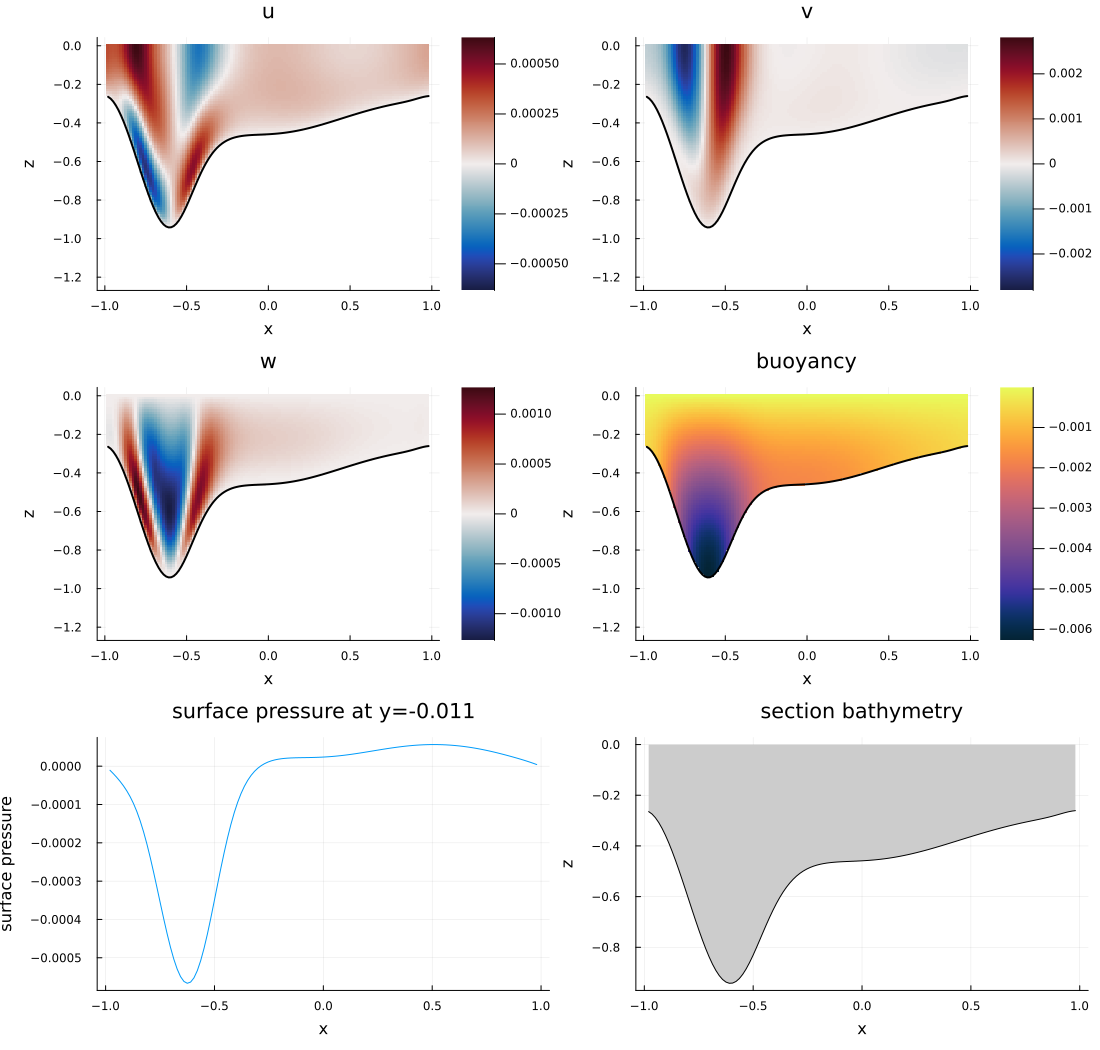

In [8]:
section_y_index = argmin(abs.(fields.y))
section_y = fields.y[section_y_index]
section_depth = fields.depth[:, section_y_index]
section_pressure = fields.surface_pressure[:, section_y_index]

function section_map(values, title; signed=true)
    finite = filter(isfinite, vec(values))
    options = signed ? (
        color=:balance,
        clims=(-maximum(abs, finite), maximum(abs, finite)),
    ) : (color=:thermal,)
    panel = heatmap(
        fields.x, fields.z, values'; xlabel="x", ylabel="z",
        title=title, options...,
    )
    plot!(panel, fields.x, -section_depth; color=:black, linewidth=2, label=false)
    return panel
end

section_u = fields.u[:, section_y_index, :]
section_v = fields.v[:, section_y_index, :]
section_w = fields.w[:, section_y_index, :]
section_b = fields.b[:, section_y_index, :]
pressure_panel = plot(
    fields.x, section_pressure; xlabel="x", ylabel="surface pressure",
    title="surface pressure at y=$(round(section_y; digits=3))", label=false,
)
depth_panel = plot(
    fields.x, -section_depth; xlabel="x", ylabel="z",
    title="section bathymetry", color=:black, fillrange=0,
    fillcolor=:gray80, label=false,
)

fram_section_figure = plot(
    section_map(section_u, "u"),
    section_map(section_v, "v"),
    section_map(section_w, "w"),
    section_map(section_b, "buoyancy"; signed=false),
    pressure_panel,
    depth_panel;
    layout=(3, 2), size=(1100, 1050),
)
if SAVE_OUTPUT
    savefig(fram_section_figure, output_path("double_basin_fram_section.png"))
end
display(fram_section_figure)

## Shared diagnostic fields

All budget calculations reuse this modest diagnostic grid and the resulting stress and transport samples.

┌ Info: PG diagnostic calculation started
│   Nx = 65
│   Ny = 65
│   horizontal_points = 4225
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1766
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:370
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 0

(streamfunction = (finite_element_setup = (seconds = 0.014861875, allocated_mib = 8.52996826171875, gc_seconds = 0.0), current_projection = (seconds = 346.333283959, allocated_mib = 16698.520538330078, gc_seconds = 0.769713162), operator_assembly = (seconds = 0.048693958, allocated_mib = 20.439193725585938, gc_seconds = 0.0), linear_solve = (seconds = 0.138275208, allocated_mib = 132.92169189453125, gc_seconds = 0.005095833), total_seconds = 346.53490710258484), bottom_stress_projection = (setup = (seconds = 0.005321125, allocated_mib = 4.6826324462890625, gc_seconds = 0.0), interpolation = (seconds = 426.611866, allocated_mib = 295814.7897949219, gc_seconds = 11.631931562), total_seconds = 426.61640214920044), sampling = (seconds = 39.517809208, allocated_mib = 10456.057876586914, gc_seconds = 0.498338085), total_seconds = 812.6696059703827, wet_points = 3553, points_per_second = 89.90883025167116, transport_projection_relative_l2 = 0.10152353724935219)

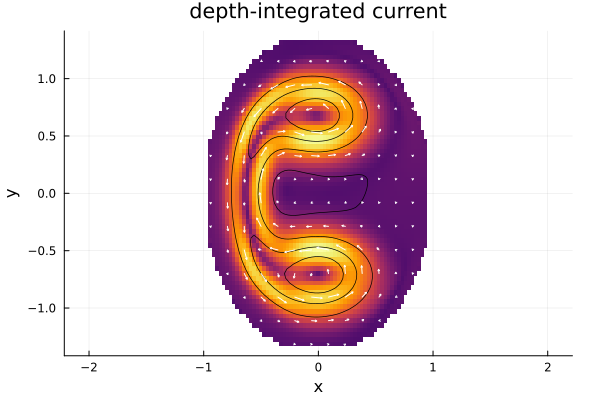

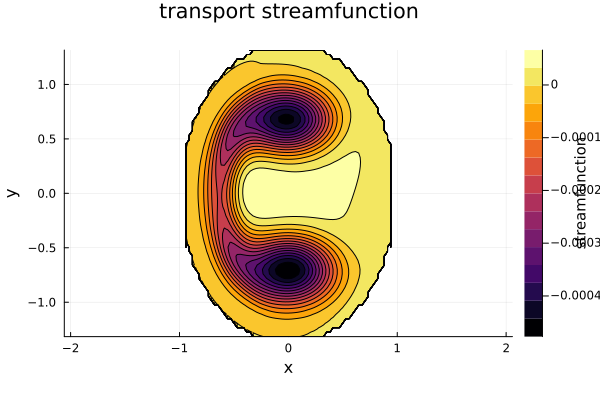

In [16]:
diagnostic_x = range(-0.94ax, 0.94ax; length=diagnostic_points)
diagnostic_y = range(-0.94ay, 0.94ay; length=diagnostic_points)
diagnostics = compute_diagnostics(solution, diagnostic_x, diagnostic_y)
display(performance_summary(diagnostics))

display(plot_depth_integrated_current(
    diagnostics; arrow_scale=0.70,
    output=output_path("double_basin_transport.png"),
))
display(plot_streamfunction(
    diagnostics;
    output=output_path("double_basin_streamfunction.png"),
))

## Budget closure diagnostics

Retain the depth-integrated momentum balance and the barotropic, depth-integrated, geostrophic-contour, and transport-divergence vorticity balances from the API example.

In [17]:
dim = compute_dim_diagnostics(solution, diagnostics)
barotropic_vorticity = compute_barotropic_vorticity_diagnostics(solution, diagnostics)
vorticity = compute_vorticity_diagnostics(solution, diagnostics)
gcvb = compute_geostrophic_contour_vorticity_diagnostics(solution, diagnostics)
tdvb = compute_transport_divergence_vorticity_diagnostics(solution, diagnostics)

closure = (
    momentum_x=dim.timings.x_relative_l2_residual,
    momentum_y=dim.timings.y_relative_l2_residual,
    barotropic_vorticity=barotropic_vorticity.timings.relative_l2_residual,
    depth_integrated_vorticity=vorticity.timings.relative_l2_residual,
    geostrophic_contour_vorticity=gcvb.timings.relative_l2_residual,
    transport_divergence_vorticity=tdvb.timings.relative_l2_residual,
)
display(closure)

┌ Info: DIM diagnostic calculation started
│   Nx = 65
│   Ny = 65
│   wet_points = 3553
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1860
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 65
│   percent = 1.5
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1885
┌ Info: DIM diagnostic sampling progress
│   rows_complet

(momentum_x = 1.0759381694085726e-5, momentum_y = 4.214724342506212e-6, barotropic_vorticity = 0.2870473757950927, depth_integrated_vorticity = 0.9202625667622645, geostrophic_contour_vorticity = 0.37674134433910644, transport_divergence_vorticity = 0.2870473757950927)

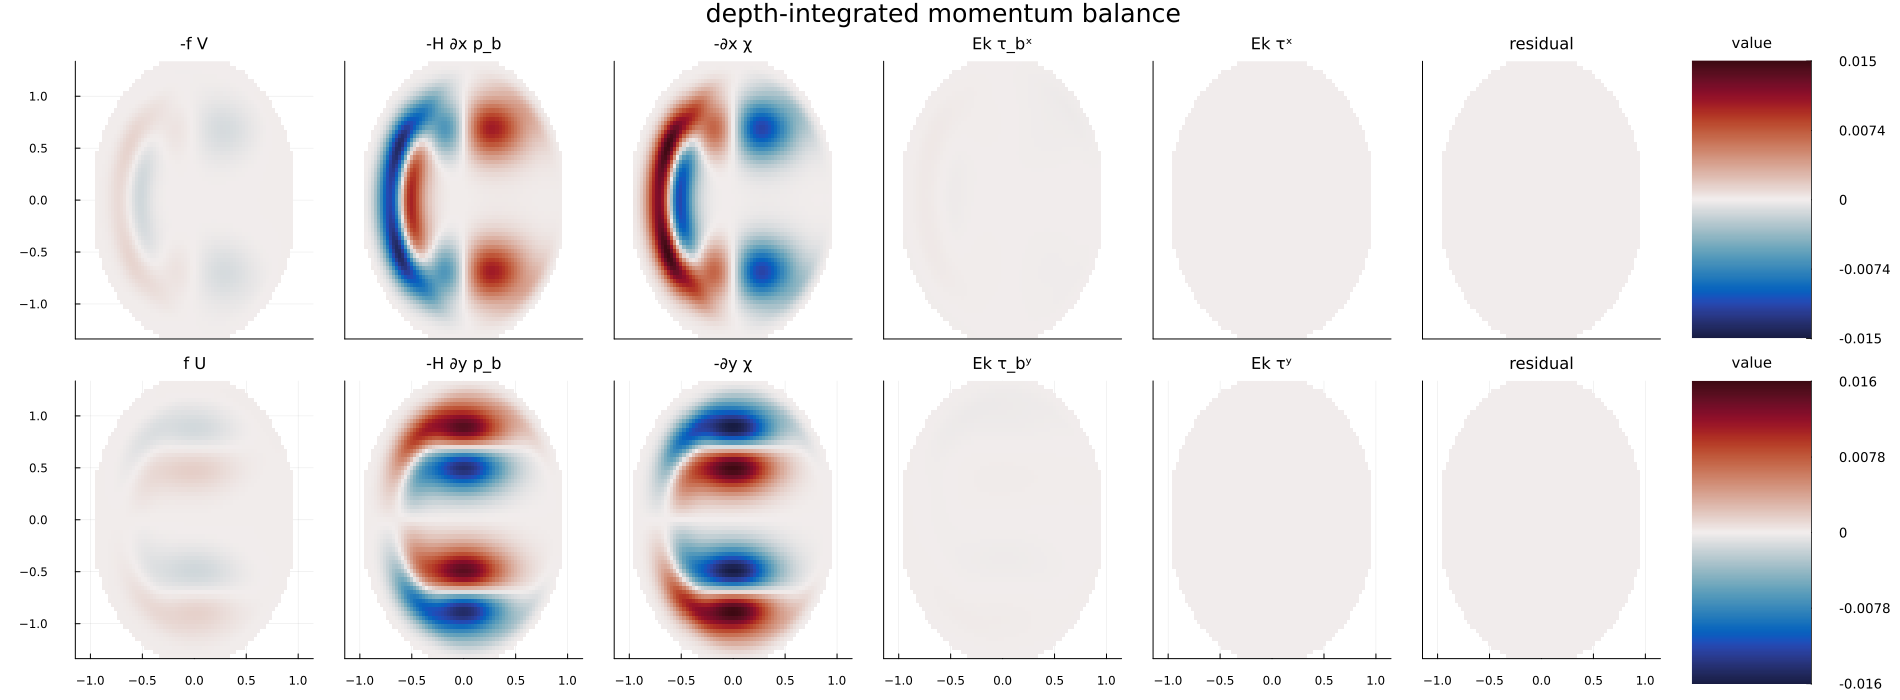

┌ Info: Plotting depth-integrated momentum balance
│   component = both
│   output = nothing
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:3180
┌ Info: Starting rendering DIM balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:16
┌ Info: Completed rendering DIM balance plot
│   seconds = 0.011
│   allocated_mib = 4.43
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:19
┌ Info: Plotting barotropic vorticity balance
│   output = n

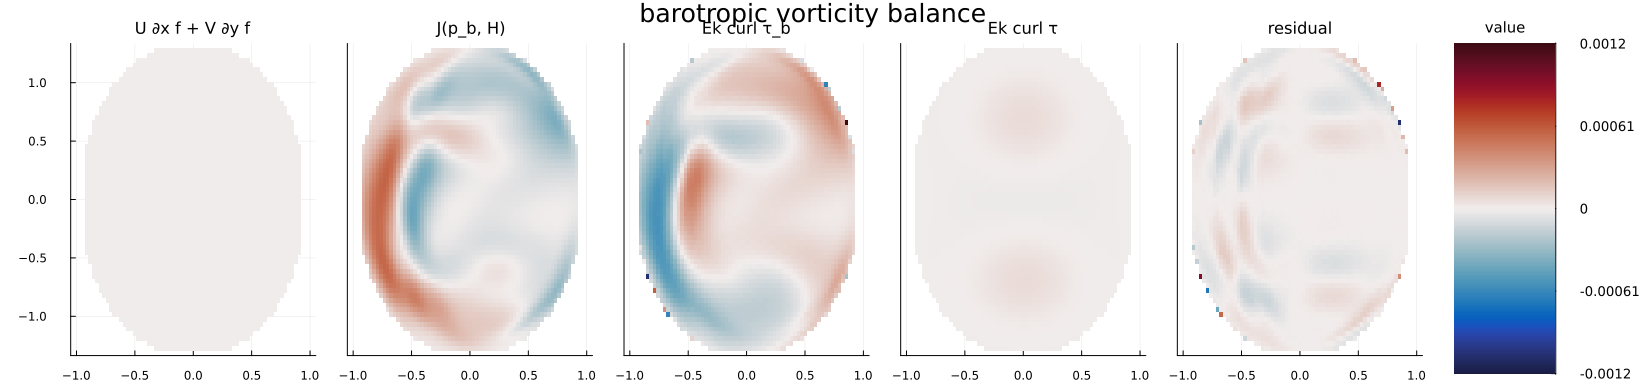

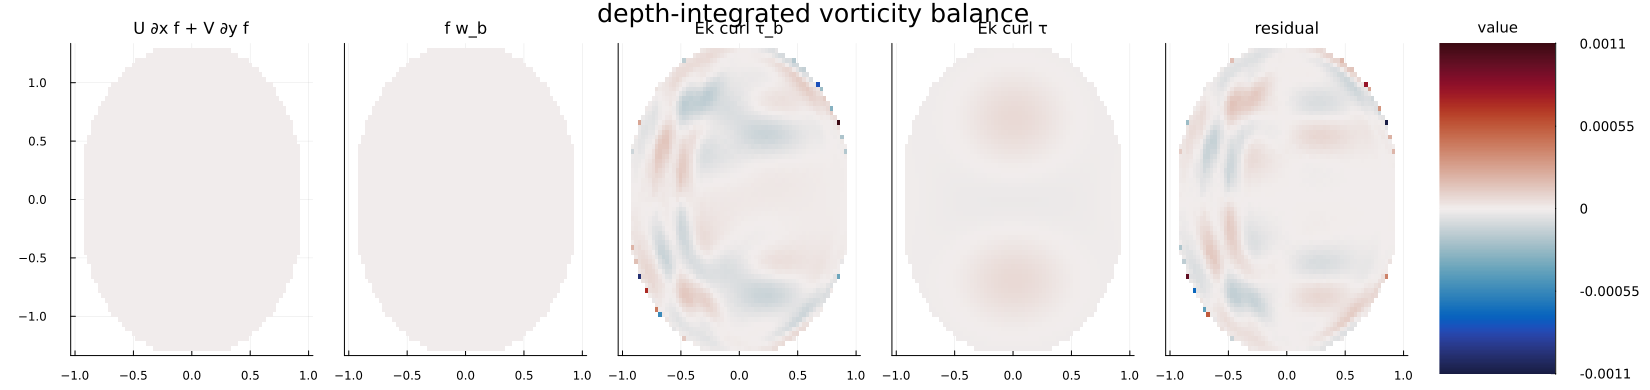

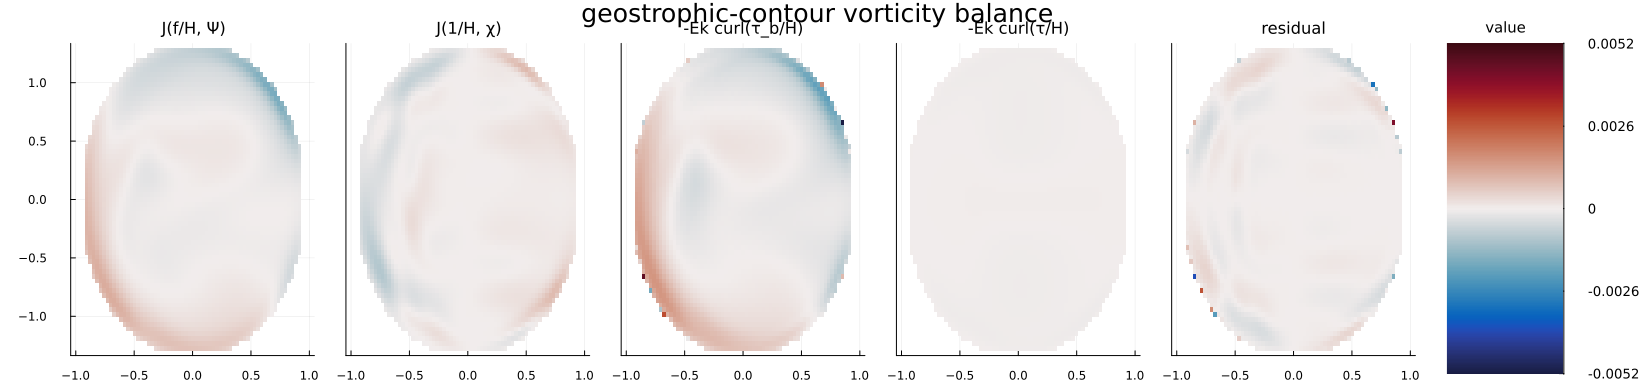

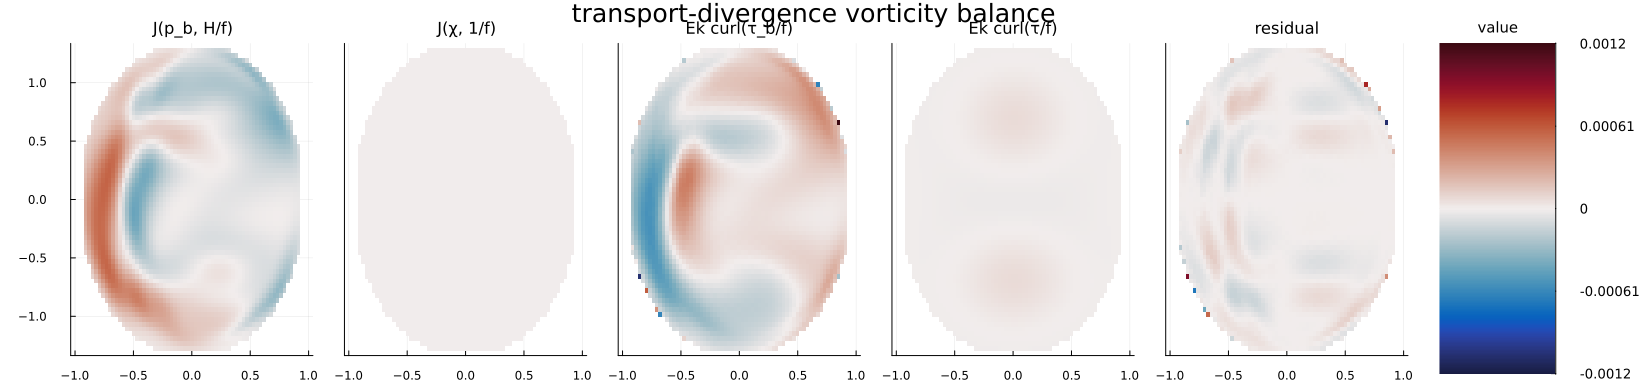

In [18]:
display(plot_dim_balance(
    dim; output=output_path("double_basin_dim_balance.png"),
))
display(plot_barotropic_vorticity_balance(
    barotropic_vorticity;
    output=output_path("double_basin_barotropic_vorticity_balance.png"),
))
display(plot_vorticity_balance(
    vorticity; output=output_path("double_basin_vorticity_balance.png"),
))
display(plot_geostrophic_contour_vorticity_balance(
    gcvb;
    output=output_path("double_basin_geostrophic_contour_vorticity_balance.png"),
))
display(plot_transport_divergence_vorticity_balance(
    tdvb;
    output=output_path("double_basin_transport_divergence_vorticity_balance.png"),
))

## Nøst & Isachsen (2003) comparison

Nøst & Isachsen split the depth-integrated transport into thermal-wind, ageostrophic, and bottom-geostrophic parts and assume $p_b=p_b(q)$ for $q=f/H$. Their bottom-geostrophic velocity is

$$\mathbf{u}_{b,g}^{NI}=\frac{1}{f}\frac{dp_b}{dq}\,\mathbf{k}\times\nabla q.$$

The calculation below diagnoses global effective linear and quadratic drag coefficients from the PG bottom stress, evaluates both closed-contour predictions independently of the PG bottom-pressure field, and tests the associated prediction $J(p_b,H/f)=0$.

In [19]:
include(joinpath(@__DIR__, "NostIsachsenDiagnostics.jl"))

nost_isachsen = NostIsachsenDiagnostics.compute_nost_isachsen_diagnostics(
    solution, diagnostics, dim, tdvb,
)
display(nost_isachsen.metrics)

(comparison_points = 2771, calibrated_linear_drag = 0.01678324455446456, calibrated_quadratic_drag = 1.3738582839964146, stress_velocity_alignment = -0.028187563503973237, linear_relative_l2_velocity_error = 1.0073270734592785, quadratic_relative_l2_velocity_error = 1.0797709210589383, linear_speed_correlation = -0.2849347496625378, quadratic_speed_correlation = -0.08212347496385283, relative_l2_cross_q_velocity = 0.0160793268619565, pg_tdvb_relative_residual = 0.2870473757950927, ni_zero_pressure_torque_relative_residual = 0.9877430274890655)

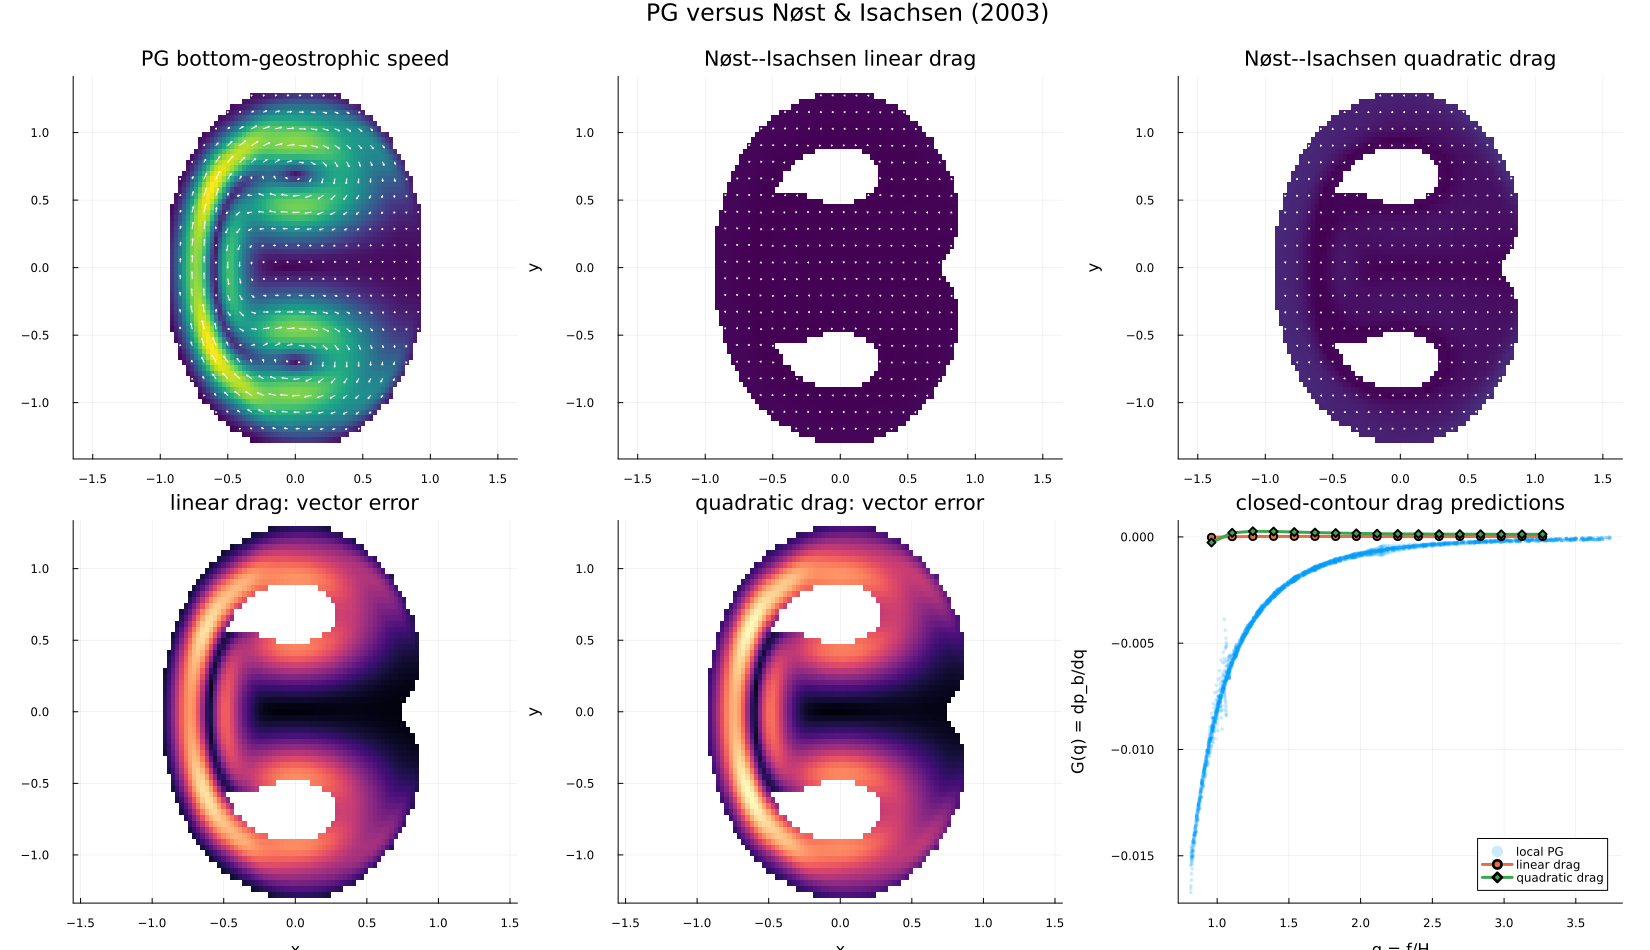

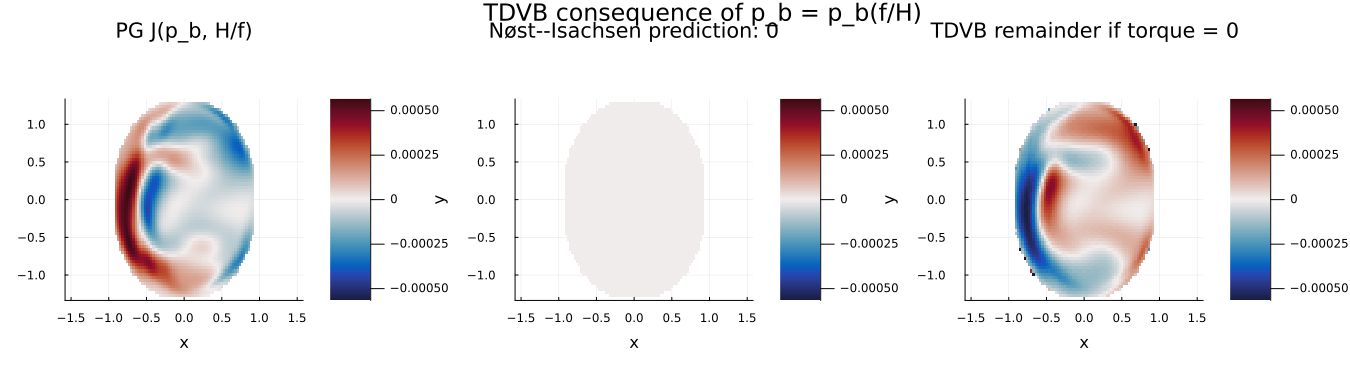

In [20]:
nost_isachsen_figures = NostIsachsenDiagnostics.plot_nost_isachsen_diagnostics(
    nost_isachsen;
    output_prefix=SAVE_OUTPUT ? joinpath(@__DIR__, "double_basin_nost_isachsen") : nothing,
)
display(nost_isachsen_figures.velocity)
display(nost_isachsen_figures.tdvb)

## Automated closure checks

These smoke tests catch failed or empty diagnostics without imposing a final production-resolution tolerance. Tight closure thresholds should be selected after the mesh and sampling resolution are increased.

In [14]:
@testset "Double-basin geometry" begin
    symmetry_x = range(-0.9ax, 0.9ax; length=17)
    symmetry_y = range(0.0, 0.9ay; length=17)
    @test all(
        isapprox(depth(xx, yy), depth(xx, -yy); rtol=1e-12, atol=1e-12)
        for xx in symmetry_x, yy in symmetry_y
    )

    barents_x = range(-Lx / 6, 0.95ax; length=65)
    barents_depth = [depth(xx, 0.0) for xx in barents_x]
    @test all(diff(barents_depth) .<= 1e-8)

    fram_x, fram_y, δ = -0.60, 0.0, 1e-3
    fram_xx = (depth(fram_x + δ, fram_y) - 2depth(fram_x, fram_y) +
        depth(fram_x - δ, fram_y)) / δ^2
    fram_yy = (depth(fram_x, fram_y + δ) - 2depth(fram_x, fram_y) +
        depth(fram_x, fram_y - δ)) / δ^2
    @test fram_xx < 0
    @test fram_yy > 0
    @test depth(fram_x, fram_y) < depth(north_basin.cx, north_basin.cy)
    @test depth(fram_x, fram_y) < depth(south_basin.cx, south_basin.cy)
end

@testset "PG budget closure smoke tests" begin
    @test count(diagnostics.wet) > 0
    @test count(barotropic_vorticity.wet) > 0
    @test count(vorticity.wet) > 0
    @test count(gcvb.wet) > 0
    @test count(tdvb.wet) > 0
    @test all(isfinite, values(closure))
end

Test Summary:         | Pass  Total  Time
Double-basin geometry |    6      6  0.2s
Test Summary:                 | Pass  Total  Time
PG budget closure smoke tests |    6      6  0.0s


Test.DefaultTestSet("PG budget closure smoke tests", false, true, false, "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/AnalyticalModel/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_Y124sZmlsZQ==.jl", 1.79045224103883e9, Random.Xoshiro(0x7caa8d50fb326c33, 0x0bb1d2d236233431, 0x2c9796546015ec05, 0x79b50a525321bedd, 0xd2a93dadc3f5dcea), 6, 1.790452241055265e9, 0x01, ReentrantLock(), Any[])